# Author: Jaime Corzo Galdó

## Homework Lecture 2

1) Simulate the daily time series for
Coke and for Pepsi over the next year.
Be clear with your assumptions and
how you arrived at them

2) Compare the year end histograms for
both simulations

3) Download historical data fo KO and
PEP. Calculate the weekly returns for
the past 10 years. Draw the QQ-Plot
of KO vs PEP. Do they come from the
same distribution?

4) Calculate the difference in weekly
returns between KO and PEP. Does
this come from a normal distribution?

In [1]:
%pip install -q yfinance


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, probplot
from pathlib import Path

rng = np.random.default_rng(42)
tickers = ["KO", "PEP"]


## 1. Assumptions

- Starting prices: October 2, 2026 closes, **\$85.65 for KO** and **\$125.89 for PEP**.
- Betas and annual dividend yields: Yahoo Finance, as shown in the table below.
- Volatility: average call and put IV at strikes of \$85 for KO and \$125 for PEP, with expiration on September 17, 2027. The quotes were collected on October 6, so this uses inputs from nearby dates. No volatility-risk-premium adjustment is made.
- Risk-free rate: **5.28%**, the October 2 ten-year Treasury yield.
- Market risk premium: **4.20%**, Damodaran's October 1 estimate (*Trailing 12 month, with adjusted payout*).
- Parameters are constant. KO and PEP are simulated independently.

CAPM gives the expected total return. I subtract the dividend yield to estimate the price drift:

$$
\mu = r_f + \beta\,ERP - q,
\qquad
\sigma = \frac{IV_{\mathrm{call}} + IV_{\mathrm{put}}}{2}.
$$

These annual estimates are used as the model's drift and volatility.


In [3]:
rf = 0.0528
ERP = 0.0420

parameters = pd.DataFrame({
    "S0": [85.65, 125.89],
    "beta": [0.32, 0.36],
    "q": [0.0245, 0.0471],
    "IV_call": [0.2480, 0.2474],
    "IV_put": [0.1904, 0.2345],
}, index=tickers)

parameters["mu"] = rf + parameters["beta"] * ERP - parameters["q"]
parameters["sigma"] = (parameters["IV_call"] + parameters["IV_put"]) / 2
display(parameters.round(5))


,S0,beta,q,IV_call,IV_put,mu,sigma
KO,85.65,0.32,0.0245,0.2480,0.1904,0.04174,0.21920
PEP,125.89,0.36,0.0471,0.2474,0.2345,0.02082,0.24095


## 2. Daily simulations

$$
r_t = \mu\,dt + \sigma\sqrt{dt}\,Z_t,
\qquad S_{t+1}=S_t(1+r_t).
$$

There are 252 daily steps and 10,000 trials. As in the example, uniform draws are transformed into standard-normal shocks using the inverse CDF. The initial price is included as row 0.


In [4]:
n_steps = 252
n_trials = 10_000
dt = 1 / n_steps
time = np.linspace(0, 1, n_steps + 1)
S = {}

for ticker in tickers:
    p = parameters.loc[ticker]
    U = rng.random((n_steps, n_trials))
    Z = norm.ppf(U)
    returns = p.mu * dt + p.sigma * np.sqrt(dt) * Z
    prices = p.S0 * np.cumprod(1 + returns, axis=0)
    S[ticker] = np.vstack([np.full(n_trials, p.S0), prices])


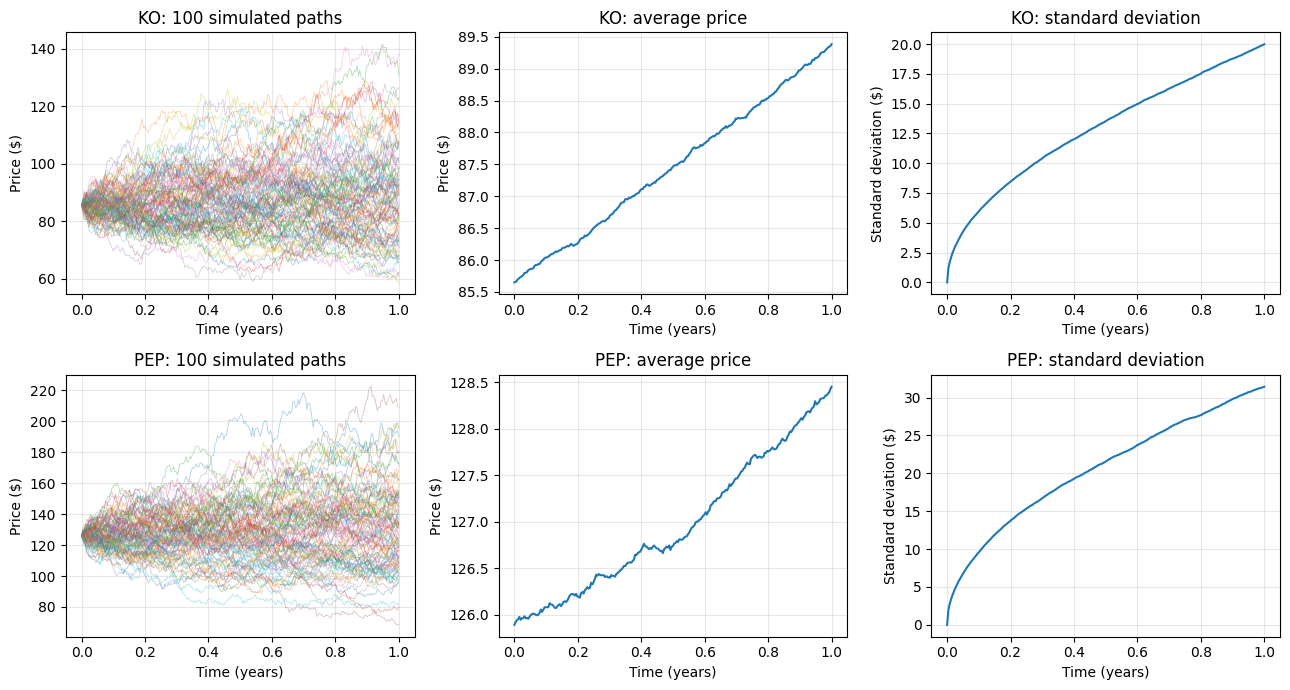

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for row, ticker in enumerate(tickers):
    axes[row, 0].plot(time, S[ticker][:, :100], alpha=0.35, linewidth=0.6)
    axes[row, 0].set_title(f"{ticker}: 100 simulated paths")
    axes[row, 0].set_ylabel("Price ($)")

    axes[row, 1].plot(time, S[ticker].mean(axis=1))
    axes[row, 1].set_title(f"{ticker}: average price")
    axes[row, 1].set_ylabel("Price ($)")

    axes[row, 2].plot(time, S[ticker].std(axis=1, ddof=1))
    axes[row, 2].set_title(f"{ticker}: standard deviation")
    axes[row, 2].set_ylabel("Standard deviation ($)")

for ax in axes.flat:
    ax.set_xlabel("Time (years)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Year-end histograms

The last row contains one final price for each trial. I compare these prices for KO and PEP.


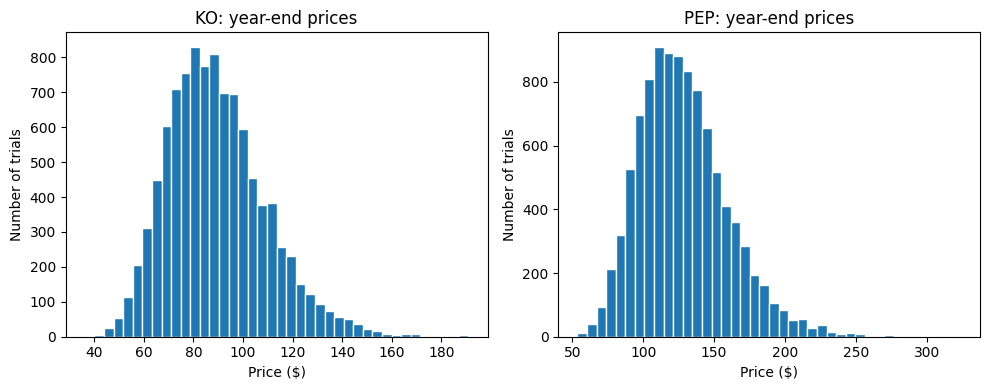

,KO,PEP
mean,89.38,128.45
std,19.99,31.43


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, ticker in zip(axes, tickers):
    ax.hist(S[ticker][-1], bins=40, edgecolor="white")
    ax.set_title(f"{ticker}: year-end prices")
    ax.set_xlabel("Price ($)")
    ax.set_ylabel("Number of trials")

plt.tight_layout()
plt.show()

final_prices = pd.DataFrame({ticker: S[ticker][-1] for ticker in tickers})
display(final_prices.agg(["mean", "std"]).round(2))


Both histograms are right-skewed. PEP has a wider distribution in dollars, partly because its initial price is higher. Its assumed percentage volatility is also higher. KO has the higher expected price growth because its dividend yield is lower after subtracting dividends from CAPM.


## 4. Weekly historical returns

I use ten years of Yahoo Finance prices, adjusted for dividends and splits. The last available common close of each week is used, with weeks ending on Friday.

Weekly log returns are calculated as

$$
r_t = \log\left(\frac{P_t}{P_{t-1}}\right).
$$

The download includes a few extra days before the ten-year window to calculate the first weekly return.


In [7]:
if Path("KO_PEP_daily_prices.csv").exists():
    data = pd.read_csv("KO_PEP_daily_prices.csv", index_col="Date", parse_dates=True)
    prices = data[["KO_AdjClose", "PEP_AdjClose"]].copy()
    prices.columns = tickers
else:
    import yfinance as yf
    prices = yf.download(tickers, start="2016-09-23", end="2026-10-03",
                         auto_adjust=True, progress=False)["Close"][tickers]

weekly_prices = prices.dropna().resample("W-FRI").last()
weekly_returns = np.log(weekly_prices / weekly_prices.shift(1))
weekly_returns = weekly_returns.loc["2016-10-02":"2026-10-02"].dropna()

print("Weekly observations:", len(weekly_returns))
display(weekly_returns.agg(["mean", "std"]).round(5))


Weekly observations: 522


Ticker,KO,PEP
mean,0.00194,0.00087
std,0.02669,0.02640


## 5. QQ plot: KO versus PEP

I sort both return samples and compare matching quantiles. If the distributions are the same, the points should be close to the diagonal line.


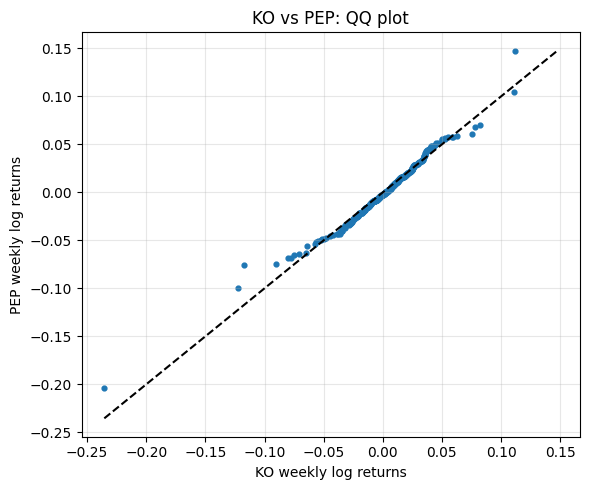

In [8]:
ko = np.sort(weekly_returns["KO"])
pep = np.sort(weekly_returns["PEP"])
low = min(ko.min(), pep.min())
high = max(ko.max(), pep.max())

plt.figure(figsize=(6, 5))
plt.scatter(ko, pep, s=12)
plt.plot([low, high], [low, high], "k--")
plt.xlabel("KO weekly log returns")
plt.ylabel("PEP weekly log returns")
plt.title("KO vs PEP: QQ plot")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The points are near the diagonal in the centre but differ in the tails. KO and PEP have similar central return distributions, but the plot does not support treating the full distributions as exactly the same.


## 6. Are weekly return differences normal?

I subtract returns from the same week:

$$
D_t = r_{KO,t} - r_{PEP,t}.
$$

A normal QQ plot should be approximately straight if these differences follow a normal distribution.


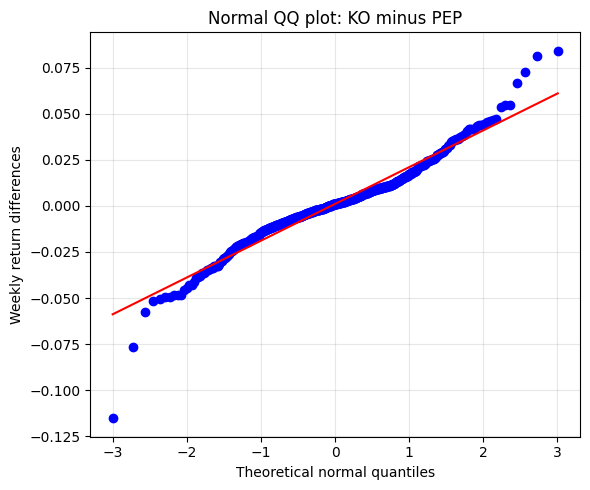

In [9]:
differences = weekly_returns["KO"] - weekly_returns["PEP"]

plt.figure(figsize=(6, 5))
probplot(differences, dist="norm", plot=plt)
plt.xlabel("Theoretical normal quantiles")
plt.ylabel("Weekly return differences")
plt.title("Normal QQ plot: KO minus PEP")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The centre is approximately straight, but both tails deviate from the line. The differences do not look normally distributed across the full sample: extreme differences are more frequent than a normal model suggests.

## Sources

- Course example: *StockPriceSimulator.html*.
- Yahoo Finance: [KO](https://finance.yahoo.com/quote/KO/), [PEP](https://finance.yahoo.com/quote/PEP/), [KO options](https://finance.yahoo.com/quote/KO/options/), and [PEP options](https://finance.yahoo.com/quote/PEP/options/).
- [U.S. Treasury daily rates](https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve): October 2, 2026, ten-year yield.
- [Damodaran](https://pages.stern.nyu.edu/adamodar/New_Home_Page/home.htm): October 1, 2026, implied ERP.
